# Sentiment Classifier Model

This file contains the trained model for a sentiment classifier that detects whether a customer review or text is **positive** or **negative**.

## Contents

- `ml_model/`: the trained model files (weights, configuration)

## Task

- **Input:** a customer review or any short text
- **Output:** a label, `positive`, `negative` or `neutral` , optionally with a confidence score

In [12]:
from cleaning import clean_text
import pandas as pd
import joblib
from sentence_transformers import SentenceTransformer
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [13]:
df = pd.read_csv('../data/training-data.csv')

In [14]:
df.head(5)

,textID,text,sentiment,Time of Tweet,Age of User,Country,Population -2020,Land Area (Km�),Density (P/Km�)
0,f87dea47db,Last session of the day http://twitpic.com/67ezh,neutral,morning,0-20,Afghanistan,38928346,652860.0,60
1,96d74cb729,Shanghai is also really exciting (precisely -...,positive,noon,21-30,Albania,2877797,27400.0,105
2,eee518ae67,"Recession hit Veronique Branquinho, she has to...",negative,night,31-45,Algeria,43851044,2381740.0,18
3,01082688c6,happy bday!,positive,morning,46-60,Andorra,77265,470.0,164
4,33987a8ee5,http://twitpic.com/4w75p - I like it!!,positive,noon,60-70,Angola,32866272,1246700.0,26


In [16]:
# Preprocessing
df['clean_text'] = df['text'].apply(clean_text)

In [17]:
df.head(5)

,textID,text,sentiment,Time of Tweet,Age of User,Country,Population -2020,Land Area (Km�),Density (P/Km�),clean_text
0,f87dea47db,Last session of the day http://twitpic.com/67ezh,neutral,morning,0-20,Afghanistan,38928346,652860.0,60,last session of the day
1,96d74cb729,Shanghai is also really exciting (precisely -...,positive,noon,21-30,Albania,2877797,27400.0,105,shanghai is also really exciting precisely sky...
2,eee518ae67,"Recession hit Veronique Branquinho, she has to...",negative,night,31-45,Algeria,43851044,2381740.0,18,recession hit veronique branquinho she has to ...
3,01082688c6,happy bday!,positive,morning,46-60,Andorra,77265,470.0,164,happy bday!
4,33987a8ee5,http://twitpic.com/4w75p - I like it!!,positive,noon,60-70,Angola,32866272,1246700.0,26,i like it!!


In [18]:
encoder = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1470.46it/s]


In [19]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

In [20]:
df['sentiment_label'] = label_encoder.fit_transform(df['sentiment'])

In [21]:
df

,textID,text,sentiment,Time of Tweet,Age of User,Country,Population -2020,Land Area (Km�),Density (P/Km�),clean_text,sentiment_label
0,f87dea47db,Last session of the day http://twitpic.com/67ezh,neutral,morning,0-20,Afghanistan,38928346,652860.0,60,last session of the day,1
1,96d74cb729,Shanghai is also really exciting (precisely -...,positive,noon,21-30,Albania,2877797,27400.0,105,shanghai is also really exciting precisely sky...,2
2,eee518ae67,"Recession hit Veronique Branquinho, she has to...",negative,night,31-45,Algeria,43851044,2381740.0,18,recession hit veronique branquinho she has to ...,0
3,01082688c6,happy bday!,positive,morning,46-60,Andorra,77265,470.0,164,happy bday!,2
4,33987a8ee5,http://twitpic.com/4w75p - I like it!!,positive,noon,60-70,Angola,32866272,1246700.0,26,i like it!!,2
...,...,...,...,...,...,...,...,...,...,...,...
3529,e5f0e6ef4b,"its at 3 am, im very tired but i can`t sleep ...",negative,noon,21-30,Nicaragua,6624554,120340.0,55,its at am im very tired but i can t sleep but ...,0
3530,416863ce47,All alone in this old house again. Thanks for...,positive,night,31-45,Niger,24206644,1266700.0,19,all alone in this old house again thanks for t...,2
3531,6332da480c,I know what you mean. My little dog is sinkin...,negative,morning,46-60,Nigeria,206139589,910770.0,226,i know what you mean my little dog is sinking ...,0
3532,df1baec676,_sutra what is your next youtube video gonna b...,positive,noon,60-70,North Korea,25778816,120410.0,214,sutra what is your next youtube video gonna be...,2


In [22]:
X = encoder.encode(df["clean_text"].tolist(), show_progress_bar=True)
y = df["sentiment_label"]

X

Batches:   0%|          | 0/111 [00:00<?, ?it/s]

Batches: 100%|██████████| 111/111 [00:22<00:00,  4.91it/s]


array([[ 0.00270627,  0.0848709 , -0.00180641, ...,  0.01956774,
        -0.11407618, -0.03057789],
       [ 0.04396914,  0.02616413,  0.07361394, ..., -0.05412112,
        -0.0502851 ,  0.09401634],
       [ 0.04070624, -0.0681011 ,  0.05307503, ..., -0.11798709,
         0.02247086, -0.00826325],
       ...,
       [ 0.14477146,  0.00731874,  0.02153921, ...,  0.03225583,
         0.01078301,  0.01665644],
       [-0.1122366 , -0.07434866, -0.00558545, ..., -0.02962828,
        -0.0705631 , -0.02884271],
       [-0.04458666,  0.05712087,  0.01481522, ..., -0.01152303,
        -0.08463625, -0.08585159]], shape=(3534, 384), dtype=float32)

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.2, random_state=12)

In [24]:
model = SVC(kernel='rbf', probability=True)

In [25]:
model.fit(X_train, y_train)

c:\Users\Admin\Documents\projects\python\td - AI\sentiment - embeddings\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [26]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

In [27]:
print("Accuracy",metrics.accuracy_score(y_train, y_train_pred))
print("Precision",metrics.precision_score(y_train, y_train_pred, average='macro'))
print("Recall",metrics.recall_score(y_train, y_train_pred, average='macro'))

Accuracy 0.9390934844192634
Precision 0.948821991017113
Recall 0.9333860149568588


In [28]:
print(metrics.classification_report(y_train, y_train_pred))

              precision    recall  f1-score   support

           0       0.98      0.91      0.95       188
           1       0.90      0.98      0.94       299
           2       0.97      0.91      0.94       219

    accuracy                           0.94       706
   macro avg       0.95      0.93      0.94       706
weighted avg       0.94      0.94      0.94       706



In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

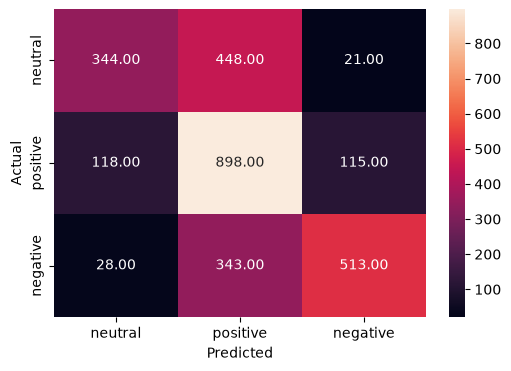

In [30]:
cm = metrics.confusion_matrix(y_test, y_test_pred)
labels = ["neutral", "positive", "negative"]
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True,  fmt='.2f', xticklabels=labels, yticklabels=labels)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

In [31]:
print("Accuracy",metrics.accuracy_score(y_test, y_test_pred))
print("Precision",metrics.precision_score(y_test, y_test_pred, average='macro'))
print("Recall",metrics.recall_score(y_test, y_test_pred, average='macro'))

Accuracy 0.6205799151343706
Precision 0.6747210684273891
Recall 0.599142864965863


### The model performs much better on the training data than on unseen data, which means it memorized the training examples instead of learning general patterns.

In [32]:
joblib.dump(model, 'svc.joblib')

['svc.joblib']

In [33]:
joblib.dump(encoder, 'encoder.joblib')

['encoder.joblib']

In [34]:
rs = model.predict([encoder.encode('I\'m happy!')])
rs

array([2])

In [35]:
s = model.predict_proba(encoder.encode(["I'm happy!"]))
model.classes_
s

array([[0.01489447, 0.05333887, 0.93176666]])